# Tutorial de Ciencia de Datos 2026
## Tutorial 6

**Objetivo:** Correr regresiones lineales. Estimar polinomios y encontrar el ECM.

Veremos:
- Repaso de Numpy y Scikit-learn
- Regresión lineal y polinómica
- Estadísticas (símil stata o R)
- Encontrar el ECM

## Regresión Lineal

La regresión lineal se trata de un **metodo de aprendizaje supervisado**. Es decir que, a diferencia lo de que veniamos viendo, ademas de tener información de un conjunto de variables o *features* ($X_1, X_2, ..., X_p$), tenemos una variable de resultado o outcome ($Y$) que queremos predecir.

La presencia de una $Y$ "objetivo" nos permite calcular el **error** de nuestro modelo al comparar directamente la $Y$ predicha con la $Y$ observada. Esto nos brinda una diferencia numerica entre los valores que predecimos y los valores reales para evaluar el desempeno de nuestro modelo.

### El modelo de Regresión Lineal Simple

$$
𝑦_i= \beta_0 + \beta_1x_i + \epsilon_i
$$

Donde:


*   $y$ = la variable a predecir
*   $x$ = la variable o *feature* para predecir a *y*
*   $\beta_0$ y $\beta_1$ = la ordenada y la pendiente de la recta
*   $\epsilon$ = todo aquello que no podemos explicar con nuestra $x$



##      NumPy y scikit-learn                   
**El paquete NumPy** es fundamental en Python. Está escrito en lenguajes de bajo nivel, lo que permite realizar operaciones matemáticas de manera muy eficiente. Para más información, ver la [guía oficial de uso de NumPy](https://docs.scipy.org/doc/numpy/user/index.html).

**El paquete scikit-learn** es una biblioteca de Python usada para machine learning, construida encima de NumPy y otros paquetes. Permite procesar datos, reducir la dimensionalidad de la base, implementar regresiones, clasificaciones, clustering y más. Pueden ver la [web de scikit-learn](https://scikit-learn.org/stable/)


In [1]:
# Importamos paquetes
#%pip install numpy==1.26.4 scipy==1.11.4
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import statsmodels.api as sm
import matplotlib.pyplot as plt

### Numpy

A continuación crearemos dos vectores con los que trabajaremos en nuestra primera regresión lineal.

In [3]:
x = np.array([5, 15, 25, 35, 45, 55])
y = np.array([5, 20, 14, 32, 22, 38])

print(x)
print(y)
print(x.shape, y.shape)
#Ambos son vectores fila

[ 5 15 25 35 45 55]
[ 5 20 14 32 22 38]
(6,) (6,)


In [5]:
# Reshape para transformar x en un vector columna
x = x.reshape((-1, 1))   # El -1 indica el largo del array
# Es equivalente a: x = x.reshape((6, 1))

print(x)
print(x.shape)

[[ 5]
 [15]
 [25]
 [35]
 [45]
 [55]]
(6, 1)


### REGRESIÓN LINEAL CON SCIKIT-LEARN
Ahora utilizaremos la función [LinearRegression()](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) del paquete scikit-learn.
    
Se pueden proveer muchos parámetros opcionales para esta función:

- **`fit_intercept`**: Booleano que decide si calcular el intercepto (True) o considerarlo igual a cero (False). Por default es True.
- **`normalize`**: Booleano que decide si normalizar las variables input (True) o no (False). Es False por default.
- **`copy_X`**: Booleano que decide si copiar (True) o sobreescribir las variables input (False). Es True por default.

In [11]:
# Primero, estimar el modelo. Lo hacemos con fit():
#Calcula beta hat y as predicciones de y
model = LinearRegression().fit(x, y)

In [13]:
# Veamos ahora los resultados

# Calculamos el R2
r2 = model.score(x, y)
print('Coeficiente de determinación:', r2)

# El intercepto
intercepto = model.intercept_
print('\nIntercepto:', intercepto)

# La pendiente
pendiente = model.coef_
print('\nPendiente:', pendiente)


Coeficiente de determinación: 0.715875613747954

Intercepto: 5.633333333333333

Pendiente: [0.54]


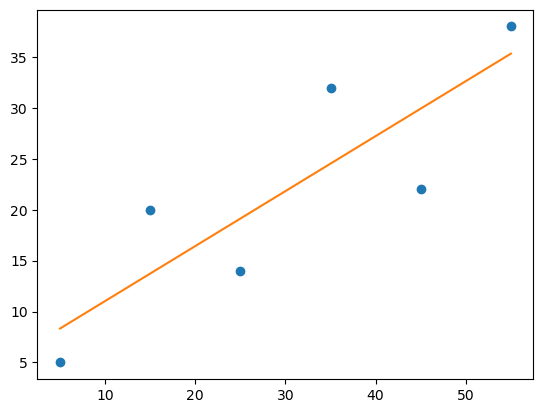

In [15]:
# Hacemos un scatter plot
plt.plot(x, y, 'o')
plt.plot(x, pendiente*x + intercepto)


#### Interpretando los coeficientes (Matemáticamente)

Como vimos, en la regresión anterior obtuvimos una pendiente $\beta_1$ = **0.54**. Esto nos indica que por cada incremente en una unidad de $x$, $y$ se incrementa en 0.54 **manteniendo todas las otras variables constantes** (aunque en este caso no hay ninguna). Por otro lado, la ordenada al origen ($\beta_0$) nos indica cual es el valor de $y$ cuando $x$ vale 0.



In [17]:
# Supongamos que ahora queremos predecir con este modelo.
# Aplicamos .predict(), usamos los valores del regresor y el modelo estimado para
# obtener la correspondiente respuesta predicha.

y_pred = model.predict(x)
print('Respuesta predicha:\n', y_pred)

# Recordemos cómo era nuestro vector y
print('\nEl vector original de y:', y)

# Con la y predicha podemos calcular el R^2 de esta otra forma
r2_new = r2_score(y, y_pred)
print("\nR2 (cálculo anterior):", r2, "\nR2 (nuevo cálculo):", r2_new)

Respuesta predicha:
 [ 8.33333333 13.73333333 19.13333333 24.53333333 29.93333333 35.33333333]

El vector original de y: [ 5 20 14 32 22 38]

R2 (cálculo anterior): 0.715875613747954 
R2 (nuevo cálculo): 0.715875613747954


In [19]:
# Si quiero probar valores nuevos de x (no los que usé para estimar el modelo):
x_new = np.arange(start=10, stop=20, step=2).reshape((-1, 1))   # Generamos valores entre [10, 20), con saltos de 2 en 2
print(x_new)

y_pred_new = model.predict(x_new)
print('\nNueva respuesta predicha:\n', y_pred_new)


[[10]
 [12]
 [14]
 [16]
 [18]]

Nueva respuesta predicha:
 [11.03333333 12.11333333 13.19333333 14.27333333 15.35333333]


#### Regresión Múltiple


In [21]:
# Para regresión lineal múltiple es lo mismo:
# Armamos un vector para la variable dependiente y una matriz de regresores:
x = np.array([[0, 1], [5, 1], [15, 2], [25, 5], [35, 11], [45, 15], [55, 34], [60, 35]])

y =  np.array([4, 5, 20, 14, 32, 22, 38, 43])

print(x)
print(y)


[[ 0  1]
 [ 5  1]
 [15  2]
 [25  5]
 [35 11]
 [45 15]
 [55 34]
 [60 35]]
[ 4  5 20 14 32 22 38 43]


In [23]:
# Estimamos el modelo
model = LinearRegression().fit(x, y)
r2 = model.score(x, y)

# Miramos resultados
print('Coeficiente de determinación:', r2)
print('\nIntercepto:', model.intercept_)
print('\nCoeficientes:', model.coef_)

Coeficiente de determinación: 0.8615939258756776

Intercepto: 5.52257927519819

Coeficientes: [0.44706965 0.25502548]


In [25]:
# Vemos la respuesta predicha para los valores originales de los regresores
y_pred = model.predict(x)
print('Respuesta predicha:', y_pred, sep='\n')

Respuesta predicha:
[ 5.77760476  8.012953   12.73867497 17.9744479  23.97529728 29.4660957
 38.78227633 41.27265006]


In [27]:
# Vemos la predicción para nuevos valores de X
x_new = np.arange(start=1, stop=31, step=3).reshape((-1, 2))   # Matriz con 2 columnas y tantas filas como tenga el array
print(x_new)
y_new = model.predict(x_new)
print('Nueva respuesta predicha:', y_new, sep='\n')

[[ 1  4]
 [ 7 10]
 [13 16]
 [19 22]
 [25 28]]
Nueva respuesta predicha:
[ 6.98975085 11.20232163 15.41489241 19.62746319 23.84003398]


### REGRESIÓN POLINÓMICA
Si queremos correr una regresión de y contra $x$ y $x^2$, necesitamos generar los datos de la nueva variable independiente.

[PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) (de scikitlearn) genera una nueva matriz que consta de todas las combinaciones polinomiales de las $x$ con un grado menor o igual al grado especificado. Por ejemplo, si una muestra de entrada es bidimensional y de la forma $[a, b]$, las características polinomiales de grado 2 son $[1, a, b, a^2, ab, b^2]$.

Se pueden cambiar varios parámetros de PolynomialFeatures:

- **`degree`** es un entero (2 por default) que representa el grado de la función de regresión polinómica.

- **`include_bias`** es un Booleano (True por default) que decide si incluir la columna de 1 que corresponde al intercepto (True) o no (False).

[Acá](https://data36.com/polynomial-regression-python-scikit-learn/) un ejemplo y una explicación más completa de cómo usarlo

In [31]:
x = np.array([5, 15, 25, 35, 45, 55]).reshape((-1, 1))   # ¿Por qué reshape?
#Cada fila es una observacion y cada columna una variable
y = np.array([15, 11, 2, 8, 25, 32])   # Vector fila
print(x)
print(y)

[[ 5]
 [15]
 [25]
 [35]
 [45]
 [55]]
[15 11  2  8 25 32]


In [33]:
model_pol = PolynomialFeatures(include_bias=False)
model_pol.fit(x)
# Aplicamos transformación a los datos. Genera una matriz de 6x2 (con x y x^2)
x_ = model_pol.transform(x)
# equivalente a: x_ = model_pol.fit_transform(x)
print(x_)

[[   5.   25.]
 [  15.  225.]
 [  25.  625.]
 [  35. 1225.]
 [  45. 2025.]
 [  55. 3025.]]


In [35]:
# Ahora usamos x_ para correr la regresión
model_pol = LinearRegression().fit(x_, y)

In [37]:
print('Coeficiente de determinación:', model_pol.score(x_, y))
print('\nIntercepto:', model_pol.intercept_)
print('\nCoeficientes:', model_pol.coef_)
#Cual es el efecto marginal?

Coeficiente de determinación: 0.8908516262498564

Intercepto: 21.37232142857143

Coeficientes: [-1.32357143  0.02839286]


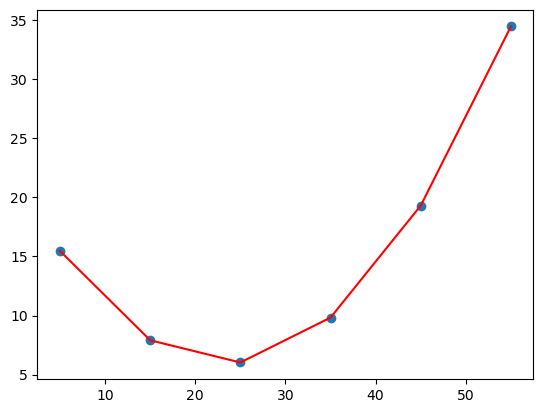

In [39]:
# Predicción
y_pred = model_pol.predict(x_)
# Graficamos
plt.scatter(x, y_pred)
plt.plot(x, y_pred, c='red')
plt.show()

### Imitando a Stata con statsmodels

[statsmodels](https://www.statsmodels.org/stable/index.html) proporciona clases y funciones para la estimación de modelos estadísticos, para realizar pruebas estadísticas y para explorar datos estadísticos.

In [53]:
x = [[0, 1], [5, 1], [15, 2], [25, 5], [35, 11], [45, 15], [55, 34], [60, 35]]
y = [4, 5, 20, 14, 32, 22, 38, 43]
x, y = np.array(x), np.array(y)

#x = sm.add_constant(x)
print(x)
print(y)

[[ 1.  0.  1.]
 [ 1.  5.  1.]
 [ 1. 15.  2.]
 [ 1. 25.  5.]
 [ 1. 35. 11.]
 [ 1. 45. 15.]
 [ 1. 55. 34.]
 [ 1. 60. 35.]]
[ 4  5 20 14 32 22 38 43]


In [55]:
# Especificamos el modelo
model = sm.OLS(y, x)
# Ajustamos el modelo
results = model.fit()

print(results.summary())
#Son estadísticamente significativos?

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.862
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     15.56
Date:                Wed, 16 Sep 2026   Prob (F-statistic):            0.00713
Time:                        09:11:33   Log-Likelihood:                -24.316
No. Observations:                   8   AIC:                             54.63
Df Residuals:                       5   BIC:                             54.87
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.5226      4.431      1.246      0.2

/opt/anaconda3/lib/python3.12/site-packages/scipy/stats/_stats_py.py:1806: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


In [59]:
# Si solo queremos ver los coeficientes
print(results.params)

[5.52257928 0.44706965 0.25502548]


In [61]:
# También lo podemos imprimir los resultados para latex
print(results.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}    &        y         & \textbf{  R-squared:         } &     0.862   \\
\textbf{Model:}            &       OLS        & \textbf{  Adj. R-squared:    } &     0.806   \\
\textbf{Method:}           &  Least Squares   & \textbf{  F-statistic:       } &     15.56   \\
\textbf{Date:}             & Wed, 16 Sep 2026 & \textbf{  Prob (F-statistic):} &  0.00713    \\
\textbf{Time:}             &     09:11:54     & \textbf{  Log-Likelihood:    } &   -24.316   \\
\textbf{No. Observations:} &           8      & \textbf{  AIC:               } &     54.63   \\
\textbf{Df Residuals:}     &           5      & \textbf{  BIC:               } &     54.87   \\
\textbf{Df Model:}         &           2      & \textbf{                     } &             \\
\textbf{Covariance Type:}  &    nonrobust     & \textbf{                     } &             \\
\bottomrule
\end{tabular}
\begin{tabular}{lcccccc}
               & \textbf{coef} & \textb

In [63]:
# Se puede obtener la respuesta predicha con los valores de x utilizados en el
# entrenamiento del modelo usando .fittedvalues o .predict():

print('predicted response:\n', results.fittedvalues) #equivalente: results.predict(x)

predicted response:
 [ 5.77760476  8.012953   12.73867497 17.9744479  23.97529728 29.4660957
 38.78227633 41.27265006]


#### Interpretando los coeficientes en Ciencia de Datos

A diferencia de la función algebraica aislada que usamos como ejemplo anteriormente ($y = 5.633 + 0.54 \cdot x$), cuando pasamos a datos reales, la interpretación de los coeficientes no es tan directa.

Al trabajar con datos reales en Ciencia de Datos, un coeficiente de regresión captura una **correlación condicional**, no un **efecto causal**, entre dos variables. Por ejemplo, como vieron en la magistral: los metros cuadrados de un departamento ($x$) y su precio ($y$). Estas variables no estan aisladas en el espacio, sino que interactúan con otras posibles características contextuales que pueden ser invisibles para nuestro modelo. Al omitir estas variables, nuestro coeficiente inevitablemente absorbe parte de sus efectos sobre la $y$ que queremos predecir.   

En este sentido, no es correcto decir cosas como "aumentar $x$ incrementa $y$" ya que:

1.   **No podemos hablar de causalidad**. Para ello, como ya vieron/van a ver en Diseños Experimentales y Cuasi-experimentales, es necesario que exista un diseño experimental (o cuasi).
2.   **No podemos "aumentar" $x$**. Estamos trabajando con una base de datos donde $x$ e $y$ son características **fijas** que le pertenecen a observaciones distintas que estamos comparando.

Por ello, la regla al trabajar con estos coeficientes es hablar de *asociaciones* y *valores esperados*. Por ejemplo, **un metro cuadrado adicional ($x$) se asocia en promedio con un cambio de $\beta_1$ en el precio ($y$).**

Con ello en mente, veamos como se interpretan otros tipos de coeficientes:

*  **Variable Dummy (Categóricas)**: Son variables que representan una condición y valen 1 si se cumple o 0 si no (la *categoría base*). Por ejemplo: Mayor de edad (si = 1, no = 0), Mujer (si = 1, no = 0), Provincia (Buenos Aires = 1, cualquier otra = 0). Al tomarse a 0 como base, el coeficiente $\beta$ representa **la diferencia en el valor esperado de $Y$ entre el "grupo 1" y el "0", menteniendo el resto constante**. Si $\beta$ > 0, significa que en promedio, el "grupo 1" tiene un valor de $Y$ mayor que el grupo base (siempre tenemos que comparar con la base).
*   **Interacciones ($x_1 \cdot x_2$)**: Cruzamos dos variables para indicarle al modelo que la asociación de $x_1$ con $y$ **depende** del valor que toma la variable **x2**. Por ejemplo, la asociación entre metros cuadrados de un departamento y su precio puede depender cambiar según su el departo es nuevo o no (dummy). En estos casos, el $\beta$ asociado ($\beta_3(x_1 \cdot x_2)$) nos va indicar **como cambia la pendiente** en base a los valores de $x$.

#### Modelo Log-Lin

En un modelo lineal estándar ($y = \beta_0 + \beta_1x$) se asume que la asociación entre $x_1$ e $y$ es **fija** para todas las observaciones. Este supuesto puede tener más o menos sentido sengún el contexto, pero suele ser irreal.

El modelo Log-Lin (Logaritmo-Lineal) se presenta como una solución: al aplicar logaritmo a la variable dependiente, el modelo asume que los cambios son **proporcionales** o **porcentuales**. De esta forma, la ecuación toma esta forma

$$ln(y) = \beta_0 + \beta_1 \cdot x_1 + ϵ$$

Acá a $\beta_1$ se lo llama **semi-elasticidad** y nos indica cómo cambia el logaritmo de $y$ ante un cambio absoluto en $x$. Para poder interpretarlo es necesario pasarlo a otro lenguaje (porcentaje):

1.   La aproximación (Variables continuas y $\beta$ pequeños): Una regla rápida para coeficientes pequeños (generalmente entre -0.1 y 0.1) es multiplar por 100. Por ejemplo, si $x_1$ son los metros cuadrados del departamento y $\beta_1 = 0.015$:

    "Manteniendo el resto constante, un metro cuadrado adicional se asocia,
    en promedio, con un aumento del 1.5% en el precio del departamento".

2.   El cálculo exacto (Dummies y $\beta$ grandes): En casos donde los coeficientes son grandes (casi siempre es el caso de las dummies), la regla anterior falla. En su lugar es necesario realizar la cuenta:
$$\% \Delta y = 100 . (e^{\beta_1} -1)$$
Por ejemplo, $x_1$ es la ubicación (Si esta en Palermo vale 1, si no vale 0) y $\beta_1 = 0.40$:
$$\% \Delta y = 100 . (e^{0.40} -1) = 49.18\%$$

    "Manteniendo el resto constante, un departamento ubicado en Palermo
    se asocia, en promedio, con precio un 49,18% mayor que uno idéntico
    en otra ubicación".


#### Ejemplo aplicando todo

In [68]:
#Simulemos un dataset de una app de delivery
# Tenemos 200 pedidos: queremos estudiar cómo la demora afecta a la propina?
#Cambia el efecto cuando está lloviendo?
np.random.seed(42)
df = pd.DataFrame({
    'demora_minutos': np.random.normal(25, 8, 200),        # Minutos que tardó el pedido
    'lluvia': np.random.binomial(1, 0.5, 200) # Dummy: 1=Llueve, 0=No llueve
})

#Evitamos tiempos de entrega irreales (min 10 minutos)
df['demora_minutos'] = np.maximum(10, df['demora_minutos'])

#Construimos la variable dependiente (Logaritmo de la propina)
#Hipótesis: La demora destruye la propina, pero la lluvia mitiga el impacto
df['log_propina'] = 5.0 - 0.04 * df['demora_minutos'] + 0.5 * df['lluvia'] + 0.025 * (df['demora_minutos'] * df['lluvia']) + np.random.normal(0, 0.1, 200)

#Ajustamos el modelo OLS con la interacción
modelo_app = smf.ols('log_propina ~ demora_minutos + lluvia + demora_minutos:lluvia', data=df).fit()
print(modelo_app.summary().tables[1])

#Calculamos los efectos marginales (La derivada del log_propina respecto a la demora)
b_demora = modelo_app.params['demora_minutos']
b_int = modelo_app.params['demora_minutos:lluvia']

#Evaluamos la derivada en los dos escenarios
penalidad = b_demora
penalidad_lluvia = b_demora + b_int * 1

print(f"\nCaída de la propina por 1 minuto extra de demora (No llueve): {penalidad * 100:.2f}%")
print(f"Caída de la propina por 1 minuto extra de demora (Llueve): {penalidad_lluvia * 100:.2f}%")

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 4.9875      0.037    133.232      0.000       4.914       5.061
demora_minutos           -0.0398      0.001    -27.336      0.000      -0.043      -0.037
lluvia                    0.5568      0.051     10.999      0.000       0.457       0.657
demora_minutos:lluvia     0.0230      0.002     11.709      0.000       0.019       0.027

Caída de la propina por 1 minuto extra de demora (No llueve): -3.98%
Caída de la propina por 1 minuto extra de demora (Llueve): -1.68%


###     ERROR CUADRÁTICO MEDIO

Ahora veamos algunas métricas de evaluación usuales para los problemas de regresión en Machine Learning.

Vamos a observar los valores de las siguientes métricas:

**Error Cuadrático Medio / Mean Squared Error**

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{f}(x_i))^2$$

El más utilizado y seguro que el que más conocen debido a que es la que emplean los algoritmos. El pincipal problema que tiene es que cambia la unidad de medida. Por ejemplo, si queremos predecir el precio de algo en pesos, el error se calcula en pesos y luego se eleva al cuadrado. Este pasaje lo hace muy dificil de interpretar.

**Raíz del Error Cuadrático Medio / Root Mean Squared Error**

$$RMSE = \sqrt{MSE}$$

Alternativa al MSE, literalmente le aplico una raíz cuadrada para obtener el valor original y poder trabajar con él. Debido a este proceso se realiza luego del promedio, le otorga una gran importancia a los valores atipicos del modelo, lo que lo vuelve **pesimista ya que penaliza fuertemente las equvocaciones extremas**

**Error Absoluto Medio / Mean Absolute Error**

$$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{f}(x_i)|$$

Similar al caso anterior, solo que uso el valor absoluto para computar el error en la unidad original. Trata a todos los errores de manera estrictamente lineal y proporcional. Equivocarse por 2.000 dólares es exactamente el doble de grave que equivocarse por 1.000. Por ello se puede tomar como una
**métrica robusta ante outliers**.

In [70]:
# Generamos un dataset aleatorio
np.random.seed(0)
x = np.random.rand(100, 1)  # Array de la forma (100, 1) con nros aleatorios entre [0, 1) de una distribución uniforme
y = 2 + 3*x + np.random.rand(100, 1)
print("x:\n", x)
print("y:\n", y)

x:
 [[0.5488135 ]
 [0.71518937]
 [0.60276338]
 [0.54488318]
 [0.4236548 ]
 [0.64589411]
 [0.43758721]
 [0.891773  ]
 [0.96366276]
 [0.38344152]
 [0.79172504]
 [0.52889492]
 [0.56804456]
 [0.92559664]
 [0.07103606]
 [0.0871293 ]
 [0.0202184 ]
 [0.83261985]
 [0.77815675]
 [0.87001215]
 [0.97861834]
 [0.79915856]
 [0.46147936]
 [0.78052918]
 [0.11827443]
 [0.63992102]
 [0.14335329]
 [0.94466892]
 [0.52184832]
 [0.41466194]
 [0.26455561]
 [0.77423369]
 [0.45615033]
 [0.56843395]
 [0.0187898 ]
 [0.6176355 ]
 [0.61209572]
 [0.616934  ]
 [0.94374808]
 [0.6818203 ]
 [0.3595079 ]
 [0.43703195]
 [0.6976312 ]
 [0.06022547]
 [0.66676672]
 [0.67063787]
 [0.21038256]
 [0.1289263 ]
 [0.31542835]
 [0.36371077]
 [0.57019677]
 [0.43860151]
 [0.98837384]
 [0.10204481]
 [0.20887676]
 [0.16130952]
 [0.65310833]
 [0.2532916 ]
 [0.46631077]
 [0.24442559]
 [0.15896958]
 [0.11037514]
 [0.65632959]
 [0.13818295]
 [0.19658236]
 [0.36872517]
 [0.82099323]
 [0.09710128]
 [0.83794491]
 [0.09609841]
 [0.97645947]
 [

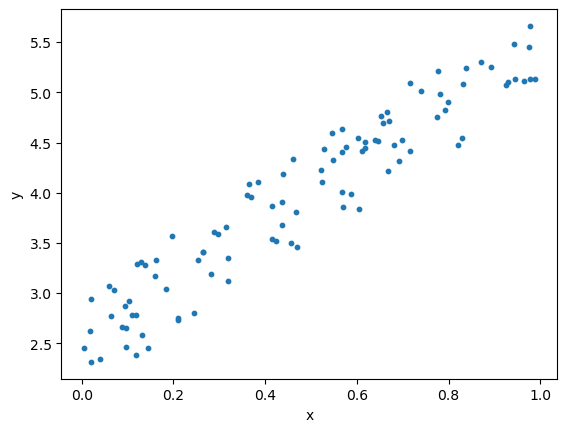

In [72]:
# Graficamos
plt.scatter(x, y, s=10)  # s indica el tamaño de los puntos del scatter.
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [74]:
x = sm.add_constant(x)
model = sm.OLS(y, x)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.904
Model:                            OLS   Adj. R-squared:                  0.903
Method:                 Least Squares   F-statistic:                     921.4
Date:                Wed, 16 Sep 2026   Prob (F-statistic):           1.22e-51
Time:                        10:12:57   Log-Likelihood:                -13.196
No. Observations:                 100   AIC:                             30.39
Df Residuals:                      98   BIC:                             35.60
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5581      0.054     47.751      0.0

In [76]:
# Predecimos las y
y_pred = results.predict(x)
y_pred

array([4.1696989 , 4.65827012, 4.32812546, 4.15815731, 3.80216397,
       4.45478107, 3.84307721, 5.17681698, 5.38792493, 3.68407562,
       4.88302102, 4.11120696, 4.22617188, 5.27614181, 2.76668104,
       2.81393966, 2.61745238, 5.00311071, 4.84317706, 5.11291512,
       5.43184275, 4.90484995, 3.91323773, 4.8501438 , 2.90539891,
       4.43724078, 2.97904427, 5.33214853, 4.09051427, 3.77575598,
       3.33496109, 4.83165679, 3.89758877, 4.22731534, 2.61325723,
       4.3717982 , 4.35553037, 4.36973821, 5.32944444, 4.56028015,
       3.61379333, 3.84144667, 4.60670965, 2.7349352 , 4.51607453,
       4.52744237, 3.17587916, 2.93667868, 3.48435148, 3.62613527,
       4.23249195, 3.84605576, 5.46049027, 2.85773982, 3.17145728,
       3.03177366, 4.47596597, 3.30188375, 3.92742542, 3.27584826,
       3.02490232, 2.88220226, 4.48542538, 2.96386132, 3.13535417,
       3.64086031, 4.96896856, 2.84322288, 5.01874803, 2.84027791,
       5.4255031 , 3.93429821, 5.42638883, 4.33423978, 4.72896

In [84]:
# Vemos el MSE

# Usando MSE de scikit-learn
mse1 = mean_squared_error(y, y_pred)
print(mse1)


0.07623324582875009


In [92]:
#Con Numpy
y_flat = y.flatten()   # Modificamos la forma de y
mse2 = np.square(np.subtract(y_flat, y_pred)).mean()
print(mse2)

0.07623324582875009


In [95]:
# También podemos ver el RMSE y el MAE
rmse = np.sqrt(mean_squared_error(y, y_pred))
print(rmse)
mae = mean_absolute_error(y, y_pred)
print(mae)

0.27610368673516494
0.23709498511190305


### Trade-off Sesgo-Varianza en Regresión Lineal

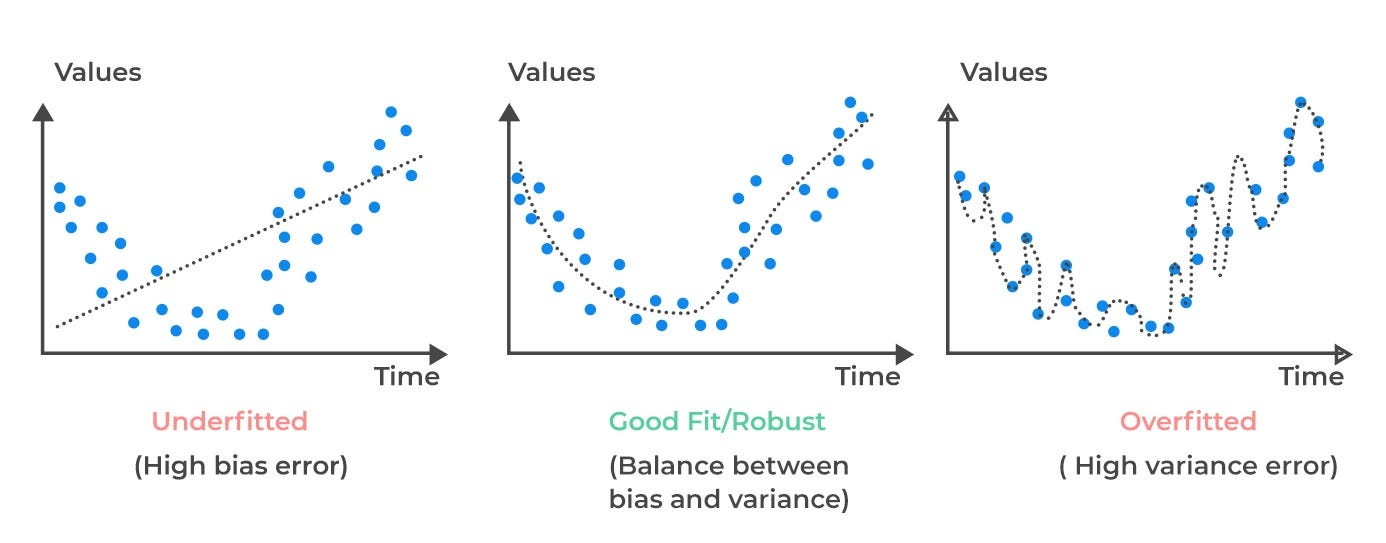

Recordemos a que nos referimos cuando hablamos de sesgo y varianza en un modelo:


1.   Sesgo: que tan bien puedo predecir/aprender de mis datos. Cuanto mas rígido es el modelo, mayor es el sesgo, más distintos serán los resultados predichos de los reales en mis datos.
2.   Varianza: que tan bien puedo aplicar lo que aprendió a datos nuevos. Cuanto mayor es la varianza, mayor será el cambio y fallarán las predicciones (Aprende del ruido de la muestra en lugar de la posible regla subyacente).

Decimos que hay un trade-off debido a que hacer un modélo muy simple para bajar la varianza va a llevar a que no logra aprender de los datos (sesgo alto), mientras que un modelo más complejo y flexible (baja el sesgo), corre el riesgo de memorizar ruido (alta varianza).


En las regresiones lineales, una de las principales formas de alterar este equilibrio es modificando la cantidad de variables (+ variables --> - sesgo), pero existen otros factores prácticos que también mueven la aguja:

*   Aumentan la Varianza (flexibilidad extrema): Trabajar con muestras muy pequeñas ($N$ bajo), introducir variables muy correlacionadas entre sí (multicolinealidad), o aplicar transformaciones polinómicas elevadas ($x^2, x^3$) que obligan a la curva a perseguir cada punto.
*   Aumentan el Sesgo (rigidez extrema): Omitir variables estructurales clave, forzar una recta sobre datos que tienen patrones curvos, o aplicar técnicas de Regularización (Ridge o Lasso, las van a ver más adelante).
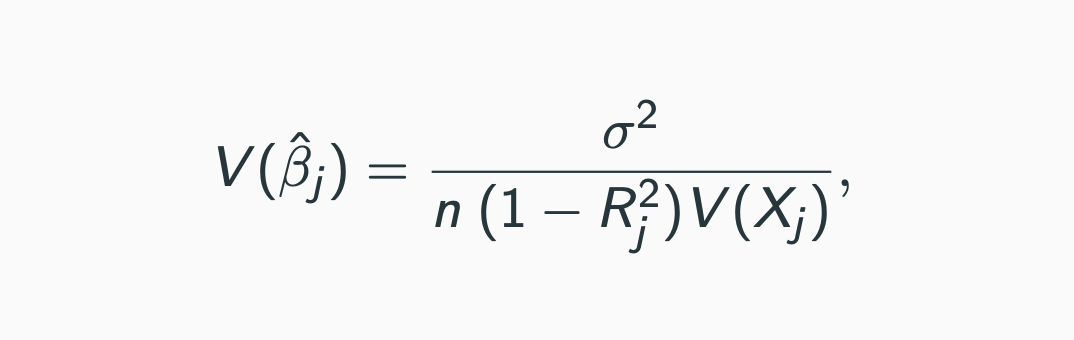
¿Cúal de los tres graficos creen que tendra el $R^2$ más alto?


### Otro ejemplo

Vamos a trabajar con la librería [ISLP](https://islp.readthedocs.io/en/latest/). En particular, lo usaremos para descargar un dataset de ejemplo. Usaremos el dataset "Boston". Pueden ver más [acá](https://islp.readthedocs.io/en/latest/datasets/Boston.html)
Tiene valores de casas (median house value) para 506 barrios alrededor de Boston
- crim: per capita crime rate by town.
- zn: proportion of residential land zoned for lots over 25,000 sq.ft.
- indus: proportion of non-retail business acres per town.
- chas: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise).
- nox: nitrogen oxides concentration (parts per 10 million).
- rm: average number of rooms per dwelling.
- age: proportion of owner-occupied units built prior to 1940.
- dis: weighted mean of distances to five Boston employment centres.
- rad: index of accessibility to radial highways.
- tax: full-value property-tax rate per USD 10,000.
- ptratio: pupil-teacher ratio by town.
- lstat: lower status of the population (percent).
- medv: median value of owner-occupied homes in 1000s USD.
   
Vamos a hacer una regresión para predecir medv


In [102]:
!pip install ISLP
# Si tienen problemas instalándolo como está en la línea anterior:
# 1) abran una nueva ventana de anaconda prompt y escriban: pip install --user ISLP
# 2) cierren jupyter notebook y vuelvan a abrirlo
# Ahora ya deberían poder usar la librería ISLP

In [104]:
from ISLP import load_data

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import statsmodels.api as sm
import matplotlib.pyplot as plt

boston = load_data("Boston")
print("Dimensión:", boston.shape,
      "\nColumnas:", boston.columns,
      "\nTipo de datos:", boston.dtypes)
boston.head()

Dimensión: (506, 13) 
Columnas: Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat', 'medv'],
      dtype='str') 
Tipo de datos: crim       float64
zn         float64
indus      float64
chas         int64
nox        float64
rm         float64
age        float64
dis        float64
rad          int64
tax          int64
ptratio    float64
lstat      float64
medv       float64
dtype: object


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [106]:
# Empezamos con un modelo de regresión simple donde rm es el regresor
y = boston['medv']   # Median value of owner-occupied homes in 1000s USD.
x = boston['rm']    # Average number of rooms per dwelling.
x

0      6.575
1      6.421
2      7.185
3      6.998
4      7.147
       ...  
501    6.593
502    6.120
503    6.976
504    6.794
505    6.030
Name: rm, Length: 506, dtype: float64

In [108]:
x = sm.add_constant(x)
x

,const,rm
0,1.0,6.575
1,1.0,6.421
2,1.0,7.185
3,1.0,6.998
4,1.0,7.147
...,...,...
501,1.0,6.593
502,1.0,6.120
503,1.0,6.976
504,1.0,6.794


In [112]:
# Ajustamos el modelo
model = sm.OLS(y, x)
results = model.fit()
print(results.summary())
print("\nConstante:", results.params['const'],
      "\nPendiente:", results.params['rm'])

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.484
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     471.8
Date:                Wed, 16 Sep 2026   Prob (F-statistic):           2.49e-74
Time:                        10:41:12   Log-Likelihood:                -1673.1
No. Observations:                 506   AIC:                             3350.
Df Residuals:                     504   BIC:                             3359.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -34.6706      2.650    -13.084      0.0

In [114]:
y_pred = results.predict(x)
mse1 = mean_squared_error(y, y_pred)
mse1

43.60055177116957

Ahora vamos con una regresión múltiple

In [116]:
y = boston['medv']
x2 = boston[boston.columns.drop('medv')]
x2 = sm.add_constant(x2)

model2 = sm.OLS(y, x2)
results2 = model2.fit()
print(results2.summary())

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.734
Model:                            OLS   Adj. R-squared:                  0.728
Method:                 Least Squares   F-statistic:                     113.5
Date:                Wed, 16 Sep 2026   Prob (F-statistic):          2.23e-133
Time:                        10:41:53   Log-Likelihood:                -1504.9
No. Observations:                 506   AIC:                             3036.
Df Residuals:                     493   BIC:                             3091.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         41.6173      4.936      8.431      0.0

In [118]:
y_pred2 = results2.predict(x2)
mse2 = mean_squared_error(y, y_pred2)
mse2

22.429681439489922

#### Hacemos una partición en la muestra y entrenamos el modelo en un conjunto de datos y lo evaluamos en otro

In [120]:
from sklearn.model_selection import train_test_split
# Realizamos el split de X e y en los sets de entrenamiento (train) y test
# Entrenaremos con el 70% de la base de datos y el resto se usarán para testear el modelo obtenido
X_train, X_test, y_train, y_test = train_test_split(x2, y, test_size=0.3, random_state=100)
# si sacamos la columna de 1 (const)
#X_train, X_test, y_train, y_test = train_test_split(x2.loc[:, x2.columns != 'const'], y, test_size=0.3, random_state=100)


In [122]:
print(f"El dataset de entrenamiento cuenta con {len(X_train)} observaciones")
print(f"El dataset de evaluación cuenta con {len(X_test)} observaciones")

El dataset de entrenamiento cuenta con 354 observaciones
El dataset de evaluación cuenta con 152 observaciones


In [124]:
print(X_train.head(4))

     const      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  \
463    1.0   5.82115   0.0  18.10     0  0.713  6.513  89.9  2.8016   24  666   
75     1.0   0.09512   0.0  12.83     0  0.437  6.286  45.0  4.5026    5  398   
478    1.0  10.23300   0.0  18.10     0  0.614  6.185  96.7  2.1705   24  666   
199    1.0   0.03150  95.0   1.47     0  0.403  6.975  15.3  7.6534    3  402   

     ptratio  lstat  
463     20.2  10.29  
75      18.7   8.94  
478     20.2  18.03  
199     17.0   4.56  


In [126]:
# Con scikit learn
model_t = LinearRegression(fit_intercept=False).fit(X_train, y_train)

In [128]:
np.set_printoptions(suppress = True) #sacamos notación científica

print("\nCoeficientes:", model_t.coef_)
for n, coef in enumerate(model_t.coef_):
    print(X_train.columns[n], round(model_t.coef_[n],3))
#print("Intercepto:", model_t.intercept_)


Coeficientes: [ 39.27212531  -0.0975138    0.04026038  -0.0148414    2.79874658
 -14.30078501   3.61767529  -0.00764     -1.3814411    0.27268803
  -0.01443288  -0.90378042  -0.4743494 ]
const 39.272
crim -0.098
zn 0.04
indus -0.015
chas 2.799
nox -14.301
rm 3.618
age -0.008
dis -1.381
rad 0.273
tax -0.014
ptratio -0.904
lstat -0.474


In [130]:
# Con statsmodels
results_t = sm.OLS(y_train, X_train).fit()
results_t.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   medv   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.735
Method:                 Least Squares   F-statistic:                     82.66
Date:                Wed, 16 Sep 2026   Prob (F-statistic):           3.43e-93
Time:                        10:44:03   Log-Likelihood:                -1030.2
No. Observations:                 354   AIC:                             2086.
Df Residuals:                     341   BIC:                             2137.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.2721      5.439      7.221      0.000      28.574      49.970
crim          -0.0975      0.043     -2.265      0.024      -0.182      -0.013
zn             0.0403      0.015      2.623      0.009       0.010       0.070
indus         -0.0148      0.072     -0.206      0.837      -0.157       0.127
chas           2.7987      0.964      2.903      0.004       0.903       4.695
nox          -14.3008      4.335     -3.299      0.001     -22.827      -5.774
rm             3.6177      0.464      7.789      0.000       2.704       4.531
age           -0.0076      0.015     -0.495      0.621      -0.038       0.023
dis           -1.3814      0.230     -6.014      0.000      -1.833      -0.930
rad            0.2727      0.078      3.490      0.001       0.119       0.426
tax           -0.0144      0.004     -3.256      0.001      -0.023      -0.006
ptratio       -0.9038      0.150     -6.033      0.000      -1.198      -0.609
lstat         -0.4743      0.056     -8.412      0.000      -0.585      -0.363
==============================================================================
Omnibus:                       71.188   Durbin-Watson:                   2.032
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              146.236
Skew:                           1.050   Prob(JB):                     1.76e-32
Kurtosis:                       5.346   Cond. No.                     1.14e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.14e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [134]:
#print("\nPvalores:\n", results_t.pvalues)
#print("\nCoeficiente de determinación:", results_t.rsquared)

In [136]:
y_train_pred = results_t.predict(X_train)
y_test_pred = results_t.predict(X_test)

mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

print("Comparamos métrica en muestra de entrenamiento: {} y de test: {}".format(mse_train, mse_test))

Comparamos métrica en muestra de entrenamiento: 19.740355427115784 y de test: 29.887207537974387
